# Engine fault detection from sound

A fleet maintenance shop could use a short engine recording to prioritize inspections. Today technicians listen to the engine and investigate reported symptoms. A missed fault can delay repairs and cause damage. A false alarm consumes technician time.

**Model and data.** Audio Spectrogram Transformer (AST) was pre-trained on AudioSet, which includes engine sounds. We adapt its pooled embeddings with a linear classifier for healthy, engine knock, and misfire. The public [KweriMoto dataset](https://huggingface.co/datasets/rayyyyy007/kwerimoto-engine-sounds) has 1,067 clips and predefined grouped splits. CLAP is an audio–text alternative evaluated in the diagnostics. The dataset card describes research and educational use and lists terms for the original sources.

**Success criteria.** Aim for ≥85% mean recall across knock and misfire, ≤20% of healthy clips flagged, and <1 second per clip on a laptop CPU. We also report how often a faulty engine is flagged for inspection regardless of fault type. All model selection uses validation; held-out evaluation comes last.

In [1]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio.functional as audio_ops
from huggingface_hub import snapshot_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from transformers import ASTFeatureExtractor, ASTForAudioClassification, ASTModel, ClapModel, ClapProcessor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "kwerimoto"
RESULTS = ROOT / "results"
CACHE, FIGURES = RESULTS / "cache", RESULTS / "figures"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)

AST_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
LABELS = ["healthy", "engine_knock", "misfire"]
HEALTHY, KNOCK, MISFIRE = range(len(LABELS))
SEED, SAMPLE_RATE = 42, 16_000
MIN_RECALL, MAX_FALSE_ALARM = 0.85, 0.20
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def batches(items, size):
    for start in range(0, len(items), size):
        yield items[start:start + size]


def show_plot(filename=None):
    if filename:
        plt.savefig(FIGURES / f"{filename}.png", dpi=200, bbox_inches="tight")
    plt.show()


set_seed(SEED)
print(f"PyTorch {torch.__version__} on {DEVICE}")

W1111 18:29:06.807000 14940 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


PyTorch 2.11.0+cu128 on cuda


## Data and leakage checks

All misfires come from Hugging Face and all AudioSet clips are knocks. Half the knock clips are synthetic AudioSet overlays on Revix recordings. These patterns give models a shortcut through recording source. We check that each recording, overlay source, and clip stays within one split. The separate `real_test` split contains only real knocks from AudioSet. Overlap with AST’s pre-training data is possible.

In [2]:
snapshot_download("rayyyyy007/kwerimoto-engine-sounds", repo_type="dataset", local_dir=DATA)
manifest = pd.read_csv(DATA / "manifest.csv")
y = manifest["label"].map({label: i for i, label in enumerate(LABELS)}).to_numpy()
source = manifest["source_dataset"].to_numpy()
synthetic = manifest["synthetic"].to_numpy()
split = {name: rows.index.to_numpy(copy=True) for name, rows in manifest.groupby("split")}
train, val = split["train"], split["validation"]

overlays = manifest[synthetic]
audioset_split = manifest[source == "audioset"].set_index("original_file")["split"]
overlay_origin = overlays["knock_source"].map(audioset_split).dropna()
leakage = {
    "recording groups": manifest.groupby("group")["split"].nunique().gt(1).sum(),
    "source recordings": manifest.groupby("source_recording")["split"].nunique().gt(1).sum(),
    "overlay knock sources": overlays.groupby("knock_source")["split"].nunique().gt(1).sum(),
    "overlays separated from their source": overlay_origin.ne(overlays.loc[overlay_origin.index, "split"]).sum(),
    "duplicate audio hashes": manifest["sha256"].duplicated().sum(),
}
assert not any(leakage.values()), leakage
print("All five leakage checks passed.")


def load_audio(filename):
    audio, rate = sf.read(DATA / filename, dtype="float32")
    assert rate == SAMPLE_RATE and audio.ndim == 1, (filename, rate, audio.shape)
    return audio


waveforms = [load_audio(filename) for filename in manifest["file_name"]]
manifest["seconds"] = [len(audio) / SAMPLE_RATE for audio in waveforms]
pd.crosstab([manifest["split"], manifest["label"]], [manifest["source_dataset"], manifest["synthetic"]])

Returning existing local_dir `C:\Users\jwm-d\Desktop\car sound fault detection\data\kwerimoto` as remote repo cannot be accessed in `snapshot_download` (Cannot reach https://huggingface.co/api/datasets/rayyyyy007/kwerimoto-engine-sounds/revision/main: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.).


All five leakage checks passed.


source_dataset          audioset huggingface revix      
synthetic                  False       False False True 
split      label                                        
real_test  engine_knock       38           0     0     0
test       engine_knock       42           0     0    43
           healthy             0          12    41     0
           misfire             0          16     0     0
train      engine_knock      199           0     0   200
           healthy             0          56   190     0
           misfire             0          76     0     0
validation engine_knock       43           0     0    43
           healthy             0          12    40     0
           misfire             0          16     0     0

## Benchmark and frozen AST baseline

The benchmark always predicts the training majority class. For the baseline, AST produces one 768-dimensional vector per recording. We standardize features using the training split, fit a linear head with AdamW, and keep the epoch with the lowest validation loss.

In [3]:
def score(rows, predicted):
    actual = y[rows]
    recalls = recall_score(actual, predicted, labels=range(len(LABELS)), average=None, zero_division=0)
    healthy, knock = actual == HEALTHY, actual == KNOCK
    overlay = synthetic[rows]
    return {
        "fault_recall": recalls[1:].mean(),
        "knock_recall": recalls[KNOCK],
        "misfire_recall": recalls[MISFIRE],
        "fault_detected": (predicted[~healthy] != HEALTHY).mean(),
        "healthy_false_alarm": (predicted[healthy] != HEALTHY).mean(),
        "macro_f1": f1_score(actual, predicted, labels=range(len(LABELS)), average="macro", zero_division=0),
        "accuracy": (predicted == actual).mean(),
        "real_knock_recall": (predicted[knock & ~overlay] == KNOCK).mean(),
        "synthetic_knock_recall": (predicted[knock & overlay] == KNOCK).mean(),
    }


def log_row(run, change, reason, predicted, tradeoff):
    return {"run": run, "change": change, "reason": reason, **score(val, predicted), "tradeoff": tradeoff}


majority = np.bincount(y[train]).argmax()
benchmark = log_row("Benchmark", "Always predict majority class", "Establish a simple reference",
                    np.full(len(val), majority), "Flags every engine as faulty")
pd.DataFrame([benchmark]).round(3)

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
0,Benchmark,Always predict majority class,Establish a simple reference,0.5,1.0,0.0,1.0,1.0,0.239,0.558,1.0,1.0,Flags every engine as faulty


In [4]:
extractor = ASTFeatureExtractor.from_pretrained(AST_ID)
ast = ASTModel.from_pretrained(AST_ID).to(DEVICE).eval()


def spectrograms(audio, tensor_type):
    return extractor(audio, sampling_rate=SAMPLE_RATE, return_tensors=tensor_type)["input_values"]


@torch.inference_mode()
def embed(audio, device=DEVICE, batch_size=16):
    return torch.cat([
        ast(spectrograms(batch, "pt").to(device)).pooler_output.float().cpu()
        for batch in batches(audio, batch_size)
    ]).numpy()


def cached_array(filename, compute):
    path = CACHE / filename
    if not path.exists():
        np.save(path, compute())
    values = np.load(path)
    assert len(values) == len(manifest), f"{path} does not match the manifest row count"
    return values


X = cached_array("ast_pooler.npy", lambda: embed(waveforms))
print(f"AST parameters: {sum(p.numel() for p in ast.parameters()) / 1e6:.1f}M")


def inference_ms(device):
    clips = [waveforms[row] for row in val[:10]]
    ast.to(device)
    embed(clips[:1], device, batch_size=1)
    start = time.perf_counter()
    embed(clips, device, batch_size=1)
    return 1000 * (time.perf_counter() - start) / len(clips)


latency = {device: inference_ms(device) for device in dict.fromkeys(["cpu", DEVICE])}
del ast
print({device: f"{ms:.0f} ms/clip" for device, ms in latency.items()})

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST parameters: 86.2M


{'cpu': '247 ms/clip', 'cuda': '33 ms/clip'}


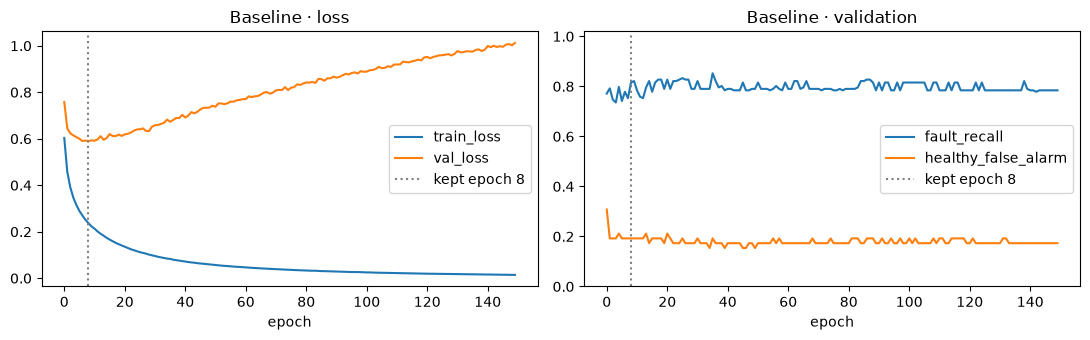

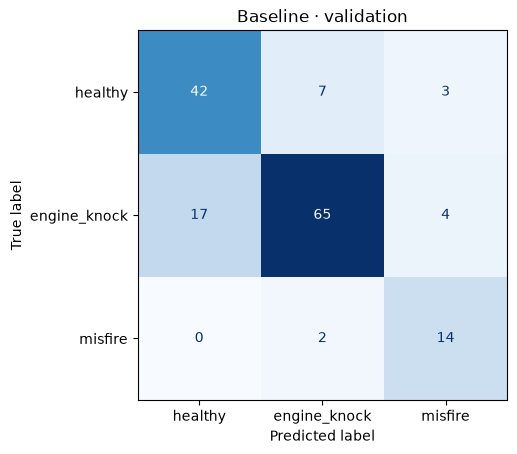

In [5]:
def standardize(train_rows):
    mean = X[train_rows].mean(0)
    scale = X[train_rows].std(0) + 1e-6
    return torch.tensor((X - mean) / scale, dtype=torch.float32, device=DEVICE)


def fit_linear(train_rows=train, val_rows=val, *, targets=y, weights=None, seed=SEED, curves=False):
    set_seed(seed)
    features = standardize(train_rows)
    labels = torch.tensor(targets, device=DEVICE)
    x_train, x_val = features[train_rows], features[val_rows]
    y_train, y_val = labels[train_rows], labels[val_rows]
    head = nn.Linear(X.shape[1], len(np.unique(targets))).to(DEVICE)
    weight = None if weights is None else torch.tensor(weights, dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weight)
    optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)

    history, best = [], (float("inf"), None, 0)
    for epoch in range(150):
        order = torch.randperm(len(x_train), device=DEVICE)
        for batch in batches(order, 64):
            optimizer.zero_grad()
            loss_fn(head(x_train[batch]), y_train[batch]).backward()
            optimizer.step()
        with torch.no_grad():
            logits = head(x_val)
            val_loss = loss_fn(logits, y_val).item()
            if curves:
                history.append({"train_loss": loss_fn(head(x_train), y_train).item(), "val_loss": val_loss,
                                **score(val_rows, logits.argmax(1).cpu().numpy())})
        if val_loss < best[0]:
            best = val_loss, {name: value.clone() for name, value in head.state_dict().items()}, epoch

    head.load_state_dict(best[1])

    @torch.no_grad()
    def predict(rows):
        return head(features[rows]).softmax(1).cpu().numpy()

    return predict, pd.DataFrame(history), best[2]


def plot_curves(history, epoch, title, filename=None):
    _, (loss, metrics) = plt.subplots(1, 2, figsize=(11, 3.5))
    history[["train_loss", "val_loss"]].plot(ax=loss, title=f"{title} · loss")
    history[["fault_recall", "healthy_false_alarm"]].plot(ax=metrics, title=f"{title} · validation",
                                                        ylim=(0, 1.02))
    for ax in (loss, metrics):
        ax.axvline(epoch, color="grey", ls=":", label=f"kept epoch {epoch}")
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    show_plot(filename)


def plot_confusion(rows, predicted, title, filename=None):
    ConfusionMatrixDisplay.from_predictions(y[rows], predicted, labels=range(len(LABELS)),
                                           display_labels=LABELS, cmap="Blues", colorbar=False)
    plt.title(title)
    show_plot(filename)


BASELINE, WEIGHTED = "Baseline", "Exp 2 (class weights)"
start = time.perf_counter()
baseline, history, epoch = fit_linear(curves=True)
baseline_seconds = time.perf_counter() - start
validation = {BASELINE: baseline(val)}
baseline_pred = validation[BASELINE].argmax(1)
baseline_log = log_row(BASELINE, "Frozen AST embeddings + linear head (lr 1e-3)", "Establish reference",
                       baseline_pred, f"2.3k trainable parameters; head trains in {baseline_seconds:.0f}s; "
                       f"{latency['cpu']:.0f} ms/clip on CPU")
plot_curves(history, epoch, BASELINE, "baseline_curves")
plot_confusion(val, baseline_pred, "Baseline · validation", "baseline_confusion")

## Three controlled experiments

| Run | Change from baseline | Expected effect |
|---|---|---|
| 1 | Train the top two AST blocks and final layer norm with the head | Better knock detection after adapting AST to engine audio |
| 2 | Weight cross-entropy by inverse class frequency | Better misfire recall, with a possible rise in false alarms |
| 3 | Remove 200 synthetic knock clips from training | Test whether the overlays help detect real knocks. This also reduces knock's share of the training set. |

Validation clips and the minimum-validation-loss checkpoint rule stay fixed. Experiment 1 uses 10 epochs, batch size 16, bfloat16 autocast, and learning rates of 2e-5 for AST and 1e-3 for the head. The two head-only experiments use the baseline's 150 epochs and batch size of 64.

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 0: train loss 0.260, validation loss 0.464


Epoch 1: train loss 0.136, validation loss 0.363


Epoch 2: train loss 0.086, validation loss 0.354


Epoch 3: train loss 0.064, validation loss 0.366


Epoch 4: train loss 0.095, validation loss 0.423


Epoch 5: train loss 0.042, validation loss 0.402


Epoch 6: train loss 0.033, validation loss 0.394


Epoch 7: train loss 0.027, validation loss 0.397


Epoch 8: train loss 0.022, validation loss 0.415


Epoch 9: train loss 0.019, validation loss 0.401


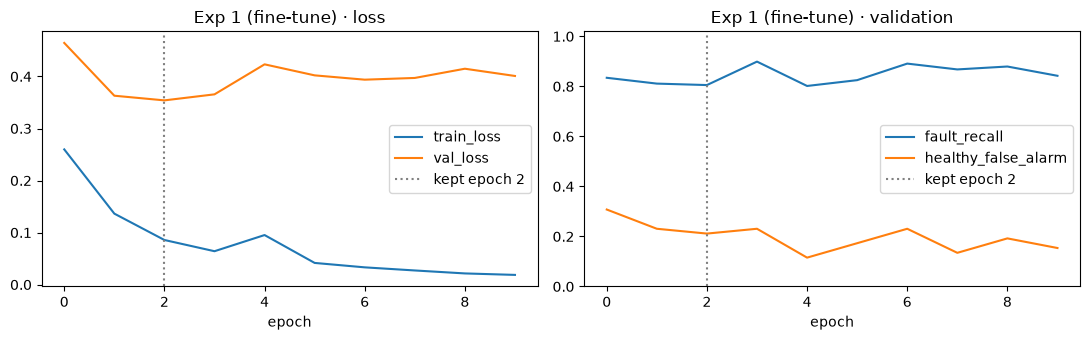

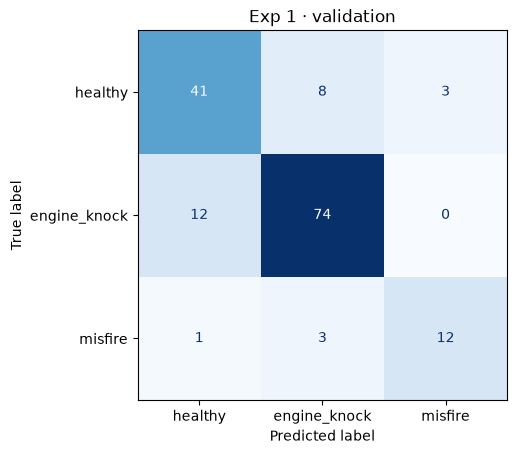

In [6]:
inputs = cached_array("ast_input_values.npy", lambda: np.concatenate([
    spectrograms(batch, "np") for batch in batches(waveforms, 64)
]).astype(np.float16))


class ASTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.ast = ASTModel.from_pretrained(AST_ID).requires_grad_(False)
        for layer in [*self.ast.layers[-2:], self.ast.layernorm]:
            layer.requires_grad_(True)
        self.head = nn.Linear(self.ast.config.hidden_size, len(LABELS))

    def forward(self, audio):
        return self.head(self.ast(audio).pooler_output)


def ast_input(rows):
    return torch.from_numpy(inputs[rows]).to(DEVICE).float()


def fit_top_layers():
    set_seed(SEED)
    model = ASTClassifier().to(DEVICE)
    trainable = {name: param for name, param in model.named_parameters() if param.requires_grad}
    optimizer = torch.optim.AdamW([
        {"params": [p for p in model.ast.parameters() if p.requires_grad], "lr": 2e-5},
        {"params": model.head.parameters(), "lr": 1e-3},
    ], weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    labels = torch.tensor(y)

    @torch.no_grad()
    def logits(rows):
        model.eval()
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            return torch.cat([model(ast_input(batch)).float().cpu() for batch in batches(rows, 32)])

    history, best = [], (float("inf"), None, 0)
    for epoch in range(10):
        model.train()
        for batch in batches(np.random.permutation(train), 16):
            with torch.autocast(DEVICE, dtype=torch.bfloat16):
                loss = loss_fn(model(ast_input(batch)), labels[batch].to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        train_loss = loss_fn(logits(train), labels[train]).item()
        val_logits = logits(val)
        val_loss = loss_fn(val_logits, labels[val]).item()
        history.append({"train_loss": train_loss, "val_loss": val_loss,
                        **score(val, val_logits.argmax(1).numpy())})
        print(f"Epoch {epoch}: train loss {train_loss:.3f}, validation loss {val_loss:.3f}")
        if val_loss < best[0]:
            best = val_loss, {name: p.detach().cpu().clone() for name, p in trainable.items()}, epoch

    model.load_state_dict(best[1], strict=False)
    return logits(val).softmax(1).numpy(), pd.DataFrame(history), best[2], sum(p.numel() for p in trainable.values())


FINE_TUNED, REAL_ONLY = "Exp 1 (fine-tune)", "Exp 3 (no synthetic)"
start = time.perf_counter()
validation[FINE_TUNED], history, epoch, parameters = fit_top_layers()
minutes = (time.perf_counter() - start) / 60
fine_tuned_pred = validation[FINE_TUNED].argmax(1)
fine_tuned_log = log_row("Exp 1", "Unfreeze top 2 AST layers (fine-tune)", "Adapt AST to engine faults",
                         fine_tuned_pred, f"{parameters / 1e6:.1f}M trainable parameters; {minutes:.1f} min to train; "
                         "ships a 345 MB model")
plot_curves(history, epoch, FINE_TUNED, "exp1_curves")
plot_confusion(val, fine_tuned_pred, "Exp 1 · validation")

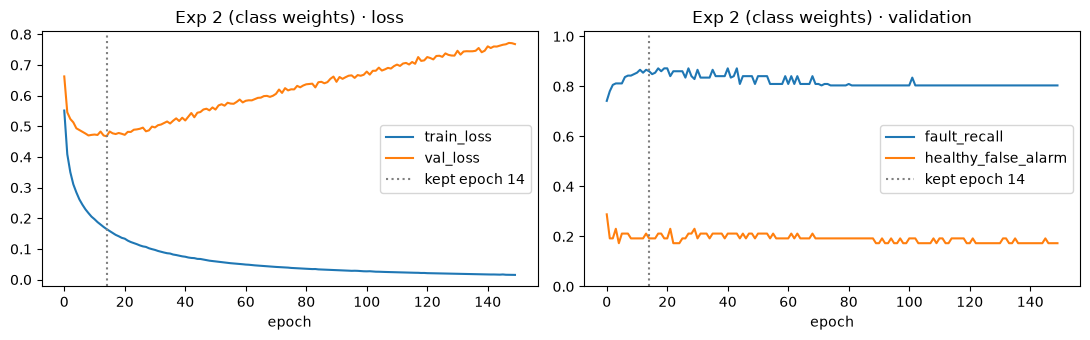

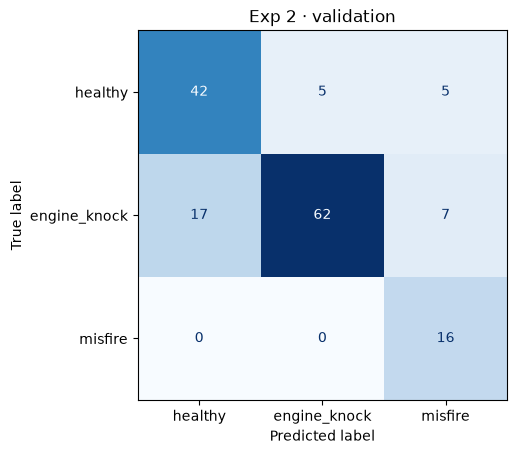

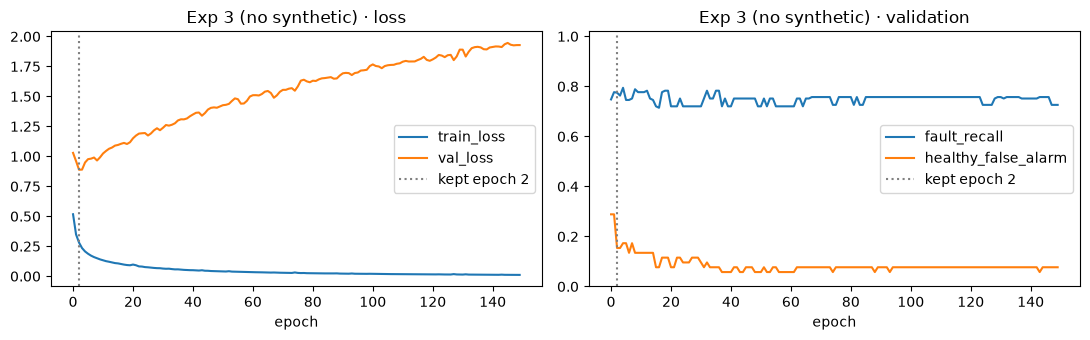

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
0,Benchmark,Always predict majority class,Establish a simple reference,0.500,1.000,0.000,1.000,1.000,0.239,0.558,1.000,1.000,Flags every engine as faulty
1,Baseline,Frozen AST embeddings + linear head (lr 1e-3),Establish reference,0.815,0.756,0.875,0.833,0.192,0.775,0.786,0.837,0.674,2.3k trainable parameters; head trains in 2s; ...
2,Exp 1,Unfreeze top 2 AST layers (fine-tune),Adapt AST to engine faults,0.805,0.860,0.750,0.873,0.212,0.804,0.825,0.907,0.814,14.2M trainable parameters; 3.0 min to train; ...
3,Exp 2,Inverse-frequency class weights,Misfires are under-represented,0.860,0.721,1.000,0.833,0.192,0.765,0.779,0.814,0.628,Same inference cost; shifts errors between cla...
4,Exp 3,Drop synthetic knocks from training,Test whether overlays help detect real knocks,0.775,0.674,0.875,0.765,0.154,0.743,0.753,0.930,0.419,Trains on 521 of 721 clips


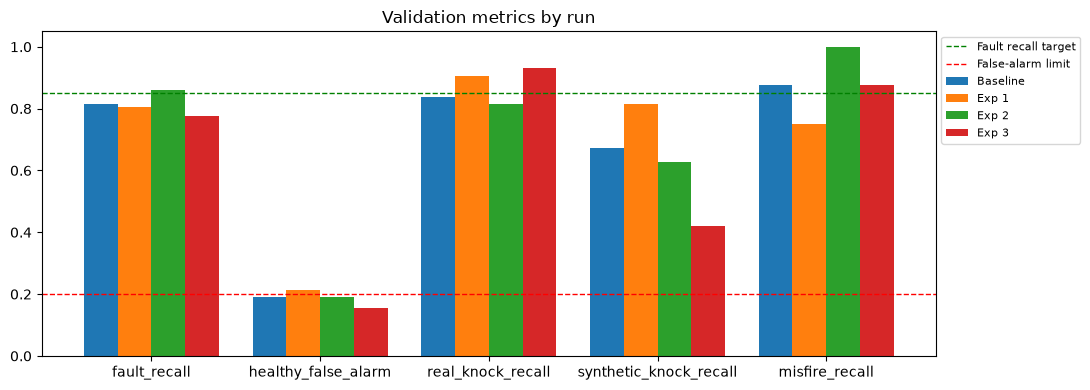

In [7]:
class_weights = len(train) / (len(LABELS) * np.bincount(y[train]))
real_train = train[~synthetic[train]]
weighted, history, epoch = fit_linear(weights=class_weights, curves=True)
validation[WEIGHTED] = weighted(val)
weighted_pred = validation[WEIGHTED].argmax(1)
plot_curves(history, epoch, WEIGHTED)
plot_confusion(val, weighted_pred, "Exp 2 · validation", "exp2_confusion")

real_only, history, epoch = fit_linear(train_rows=real_train, curves=True)
validation[REAL_ONLY] = real_only(val)
plot_curves(history, epoch, REAL_ONLY)

experiment_log = pd.DataFrame([
    benchmark, baseline_log, fine_tuned_log,
    log_row("Exp 2", "Inverse-frequency class weights", "Misfires are under-represented",
            weighted_pred, "Same inference cost; shifts errors between classes"),
    log_row("Exp 3", "Drop synthetic knocks from training", "Test whether overlays help detect real knocks",
            validation[REAL_ONLY].argmax(1), f"Trains on {len(real_train)} of {len(train)} clips"),
]).round(3)
experiment_log.to_csv(RESULTS / "experiment_log.csv", index=False)
display(experiment_log)

metrics = ["fault_recall", "healthy_false_alarm", "real_knock_recall", "synthetic_knock_recall", "misfire_recall"]
ax = experiment_log.set_index("run").drop(index="Benchmark")[metrics].T.plot.bar(figsize=(11, 4), rot=0, width=0.8)
ax.axhline(MIN_RECALL, color="green", ls="--", lw=1, label="Fault recall target")
ax.axhline(MAX_FALSE_ALARM, color="red", ls="--", lw=1, label="False-alarm limit")
ax.set(ylim=(0, 1.05), title="Validation metrics by run")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
show_plot("comparison")

- **Fine-tuning underperformed.** Knock recall rose from 76% to 86%, but two more misfires were missed and overall fault recall fell from 82% to 81%. Validation loss reached its minimum at epoch 2 while training loss kept falling. The extra training and model size favor keeping AST frozen.
- **Class weights shifted the errors.** The weighted head caught all 16 validation misfires, up from 14, while missing three more knocks. It met both validation targets at the default seed. The seed check below tests how consistently that advantage holds.
- **Removing overlays hurt synthetic-knock recall.** Real-knock recall rose from 84% to 93% while synthetic-knock recall fell from 67% to 42%. All of these real validation knocks come from AudioSet, so source cues could explain some of that gain.

## Validation prediction review

In [8]:
review = manifest.loc[val, ["file_name", "label", "source_dataset", "synthetic", "seconds"]].assign(
    predicted=np.array(LABELS)[baseline_pred],
    confidence=validation[BASELINE].max(1).round(3),
)
correct = review["label"] == review["predicted"]
errors = review[~correct].sort_values("confidence", ascending=False)
errors.to_csv(RESULTS / "baseline_val_errors.csv")
display(review[correct].sort_values("confidence", ascending=False).groupby("label").head(1))
display(errors.head(4))

,file_name,label,source_dataset,synthetic,seconds,predicted,confidence
932,prepared/validation/engine_knock/audioset_GgzF...,engine_knock,audioset,False,10.000000,engine_knock,0.998
1020,prepared/validation/healthy/revix_car_clean_00...,healthy,revix,False,10.000000,healthy,0.994
1053,prepared/validation/misfire/hf_misfire_011.wav,misfire,huggingface,False,9.322688,misfire,0.968


,file_name,label,source_dataset,synthetic,seconds,predicted,confidence
961,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,4.128000,healthy,0.968
926,prepared/validation/engine_knock/audioset_9wGJ...,engine_knock,audioset,False,10.000000,healthy,0.953
996,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,9.984000,healthy,0.945
1008,prepared/validation/healthy/hf_healthy_059.wav,healthy,huggingface,False,6.762688,misfire,0.922


- **Revix `0043`** was a 4.1 s synthetic knock predicted healthy with 97% confidence. The overlay could be masked by the underlying engine audio. In a shop, this prediction could delay inspection.
- **AudioSet `9wGJydlJvrk_30000`** was a 10 s real knock predicted healthy with 95% confidence. Even a full-length clip from the familiar knock source can be missed. The output should never override a technician's concern.
- **Hugging Face `hf_healthy_059`** was predicted misfire with 92% confidence. Normal variation in the sound or recording setup could contribute. The consequence is extra inspection time, which motivates the false-alarm limit.

## Recording-source diagnostics

A source classifier tests how easily the embeddings reveal where a clip was recorded. Within-source AUC measures whether the model ranks faulty clips above healthy clips when both share a source. The Revix comparison uses synthetic overlays, and the Hugging Face comparison has only 28 validation clips.

In [9]:
source_id, source_names = pd.factorize(source, sort=True)
for subset, train_rows, val_rows in [
    ("all clips", train, val),
    ("healthy clips", train[y[train] == HEALTHY], val[y[val] == HEALTHY]),
]:
    predict, _, _ = fit_linear(train_rows, val_rows, targets=source_id)
    accuracy = (predict(val_rows).argmax(1) == source_id[val_rows]).mean()
    majority_accuracy = pd.Series(source_id[val_rows]).value_counts(normalize=True).max()
    print(f"Source accuracy ({subset}): {accuracy:.3f}, majority benchmark: {majority_accuracy:.3f}")


WITHIN_SOURCE = {"AUC knock|Revix": ("revix", KNOCK), "AUC misfire|HF": ("huggingface", MISFIRE)}


def matching_rows(rows, recording_source, fault):
    return rows[(source[rows] == recording_source) & np.isin(y[rows], [HEALTHY, fault])]


def within_source(probabilities):
    scores = {}
    for name, (recording_source, fault) in WITHIN_SOURCE.items():
        mask = np.isin(val, matching_rows(val, recording_source, fault))
        scores[name] = roc_auc_score(y[val][mask] == fault, probabilities[mask, fault])
    return scores


def fit_probe(features, target, rows):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(features[rows], target[rows])


within_trained = {}
for name, (recording_source, fault) in WITHIN_SOURCE.items():
    train_rows = matching_rows(train, recording_source, fault)
    val_rows = matching_rows(val, recording_source, fault)
    is_fault = y == fault
    probe = fit_probe(X, is_fault, train_rows)
    within_trained[name] = roc_auc_score(is_fault[val_rows], probe.predict_proba(X[val_rows])[:, 1])

within = pd.DataFrame({name: within_source(proba) for name, proba in validation.items()}).T
within.loc["Probe trained within source"] = within_trained
within = within.round(3)
within.to_csv(RESULTS / "within_source.csv")
within

Source accuracy (all clips): 0.948, majority benchmark: 0.539


Source accuracy (healthy clips): 0.981, majority benchmark: 0.769


,AUC knock|Revix,AUC misfire|HF
Baseline,0.865,0.859
Exp 1 (fine-tune),0.905,0.854
Exp 2 (class weights),0.873,0.891
Exp 3 (no synthetic),0.701,0.781
Probe trained within source,0.876,0.938


Source is identifiable in 95% of validation clips and 98% of healthy clips. Baseline within-source AUCs of 0.87 for Revix knocks and 0.86 for Hugging Face misfires show that the embeddings also carry fault information in these comparisons.

### Zero-shot checks

AST's AudioSet head already has an `Engine knocking` output. Comparing AudioSet knocks with Revix overlays tests how much its performance varies by source. CLAP scores each recording against three text prompts. It expects 48 kHz audio, so we upsample the 16 kHz clips.

In [10]:
ast_classifier = ASTForAudioClassification.from_pretrained(AST_ID).to(DEVICE).eval()
knock_label = ast_classifier.config.label2id["Engine knocking"]
with torch.inference_mode():
    knock_scores = torch.cat([
        ast_classifier(ast_input(batch)).logits[:, knock_label].sigmoid().cpu()
        for batch in batches(val, 32)
    ]).numpy()
del ast_classifier

healthy = y[val] == HEALTHY
knock = y[val] == KNOCK
revix = source[val] == "revix"
comparisons = {
    "all knocks vs all healthy": knock | healthy,
    "audioset knocks vs all healthy": healthy | (knock & (source[val] == "audioset")),
    "revix knocks vs all healthy": healthy | (knock & revix),
    "Revix knocks vs Revix healthy (within source)": revix & (knock | healthy),
}
ast_zero_shot = pd.Series({name: roc_auc_score(knock[mask], knock_scores[mask])
                           for name, mask in comparisons.items()}, name="auc")
ast_zero_shot.to_csv(RESULTS / "ast_zero_shot.csv")
display(ast_zero_shot.round(3))

all knocks vs all healthy                        0.739
audioset knocks vs all healthy                   0.856
revix knocks vs all healthy                      0.621
Revix knocks vs Revix healthy (within source)    0.792
Name: auc, dtype: float64

In [11]:
CLAP_ID = "laion/clap-htsat-unfused"
prompts = [
    "the sound of a healthy car engine running smoothly",
    "the sound of a car engine knocking",
    "the sound of a car engine misfiring and running rough",
]
clap = ClapModel.from_pretrained(CLAP_ID).to(DEVICE).eval()
processor = ClapProcessor.from_pretrained(CLAP_ID)
text = processor(text=prompts, return_tensors="pt", padding=True)

logits = []
with torch.inference_mode():
    for rows in batches(val, 16):
        audio = [audio_ops.resample(torch.from_numpy(waveforms[row]), SAMPLE_RATE, 48_000).numpy()
                 for row in rows]
        audio_inputs = processor(audio=audio, sampling_rate=48_000, return_tensors="pt")
        batch = {key: value.to(DEVICE) for key, value in {**text, **audio_inputs}.items()}
        logits.append(clap(**batch).logits_per_audio.float().cpu())
del clap
clap_proba = torch.cat(logits).softmax(1).numpy()

clap_zero_shot = pd.Series({**score(val, clap_proba.argmax(1)), **within_source(clap_proba)}, name="value")
clap_zero_shot.to_csv(RESULTS / "clap_zero_shot.csv")
clap_zero_shot.round(3)

fault_recall              0.222
knock_recall              0.070
misfire_recall            0.375
fault_detected            0.657
healthy_false_alarm       0.654
macro_f1                  0.194
accuracy                  0.195
real_knock_recall         0.093
synthetic_knock_recall    0.047
AUC knock|Revix           0.488
AUC misfire|HF            0.776
Name: value, dtype: float64

AST scored AudioSet knocks higher against healthy clips (AUC 0.86) than Revix overlays (0.62). Both prior exposure to AudioSet and mixing into background engine audio could explain the gap. CLAP reached 22% fault recall, below the majority benchmark's 50%.

### Conditional source adversary

An encoder feeds a fault classifier and a source classifier. The source classifier sees the true fault label, and gradient reversal pushes the encoder to hide source within each label represented by multiple sources. At weight zero, the encoder receives no source gradient. We compare four weights over five seeds and train a fresh source probe on each learned representation.

In [12]:
class ReverseGradient(torch.autograd.Function):
    @staticmethod
    def forward(ctx, features, weight):
        ctx.weight = weight
        return features.view_as(features)

    @staticmethod
    def backward(ctx, grad):
        return -ctx.weight * grad, None


multi_source = [label for label in range(len(LABELS)) if len(np.unique(source[y == label])) > 1]


def fit_adversarial(weight, seed):
    set_seed(seed)
    features = standardize(train)
    labels, sources = (torch.tensor(values, device=DEVICE) for values in (y, source_id))
    conditions = nn.functional.one_hot(labels, len(LABELS)).float()
    source_rows = torch.isin(labels, torch.tensor(multi_source, device=DEVICE))
    source_train = torch.tensor(train[np.isin(y[train], multi_source)], device=DEVICE)

    encoder = nn.Sequential(nn.Linear(X.shape[1], 256), nn.ReLU(), nn.Dropout(0.2)).to(DEVICE)
    head = nn.Linear(256, len(LABELS)).to(DEVICE)
    adversary = nn.Sequential(nn.Linear(256 + len(LABELS), 64), nn.ReLU(),
                              nn.Linear(64, len(source_names))).to(DEVICE)
    params = [*encoder.parameters(), *head.parameters(), *adversary.parameters()]
    optimizer = torch.optim.AdamW(params, lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    best_loss, best_state, info = float("inf"), None, None
    for epoch in range(150):
        encoder.train()
        order = torch.tensor(np.random.permutation(train), device=DEVICE)
        for rows in batches(order, 64):
            encoded = encoder(features[rows])
            loss = loss_fn(head(encoded), labels[rows])
            mask = source_rows[rows]
            if mask.any():
                reversed_features = ReverseGradient.apply(encoded[mask], weight)
                source_logits = adversary(torch.cat([reversed_features, conditions[rows][mask]], 1))
                loss = loss + loss_fn(source_logits, sources[rows][mask])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if epoch < 30:  # Give the adversary time to influence the encoder before selecting a checkpoint.
            continue
        encoder.eval()
        with torch.no_grad():
            val_loss = loss_fn(head(encoder(features[val])), labels[val]).item()
            if val_loss < best_loss:
                source_logits = adversary(torch.cat([encoder(features[source_train]), conditions[source_train]], 1))
                accuracy = (source_logits.argmax(1) == sources[source_train]).float().mean().item()
                best_loss = val_loss
                best_state = [{name: p.clone() for name, p in module.state_dict().items()}
                              for module in (encoder, head)]
                info = {"kept_epoch": epoch, "adversary_train_acc": accuracy}

    encoder.load_state_dict(best_state[0])
    head.load_state_dict(best_state[1])
    encoder.eval()
    with torch.no_grad():
        encoded = encoder(features)
        return encoded.cpu().numpy(), head(encoded[val]).softmax(1).cpu().numpy(), info


def source_probe(features):
    scores = {}
    for label in multi_source:
        train_rows, val_rows = train[y[train] == label], val[y[val] == label]
        probe = fit_probe(features, source_id, train_rows)
        scores[f"source probe|{LABELS[label]}"] = balanced_accuracy_score(source_id[val_rows],
                                                                        probe.predict(features[val_rows]))
    return scores


print("Source probe on frozen embeddings:", pd.Series(source_probe(X)).round(3).to_dict())

Source probe on frozen embeddings: {'source probe|healthy': 1.0, 'source probe|engine_knock': 0.907}


Finished all five seeds for adversary weight 0


Finished all five seeds for adversary weight 1


Finished all five seeds for adversary weight 10


Finished all five seeds for adversary weight 30


lambda                            0.0     1.0     10.0     30.0
kept_epoch                mean  31.800  35.600  57.000  123.600
                          std    0.837   4.037  30.765   21.939
adversary_train_acc       mean   0.995   0.855   0.789    0.824
                          std    0.004   0.041   0.039    0.032
misfire_recall            mean   0.800   0.788   0.788    0.812
                          std    0.028   0.056   0.071    0.062
source probe|healthy      mean   1.000   1.000   1.000    1.000
                          std    0.000   0.000   0.000    0.000
source probe|engine_knock mean   0.851   0.900   0.907    0.912
                          std    0.025   0.021   0.016    0.010
AUC knock|Revix           mean   0.885   0.879   0.880    0.890
                          std    0.003   0.016   0.018    0.035
AUC misfire|HF            mean   0.902   0.890   0.876    0.832
                          std    0.007   0.019   0.019    0.036
fault_recall              mean   0.814   0.802   0.815    0.828
                          std    0.016   0.025   0.038    0.023
healthy_false_alarm       mean   0.185   0.204   0.246    0.215
                          std    0.017   0.029   0.053    0.021
real_knock_recall         mean   0.898   0.860   0.888    0.907
                          std    0.013   0.023   0.030    0.033
synthetic_knock_recall    mean   0.758   0.772   0.795    0.781
                          std    0.027   0.042   0.034    0.082

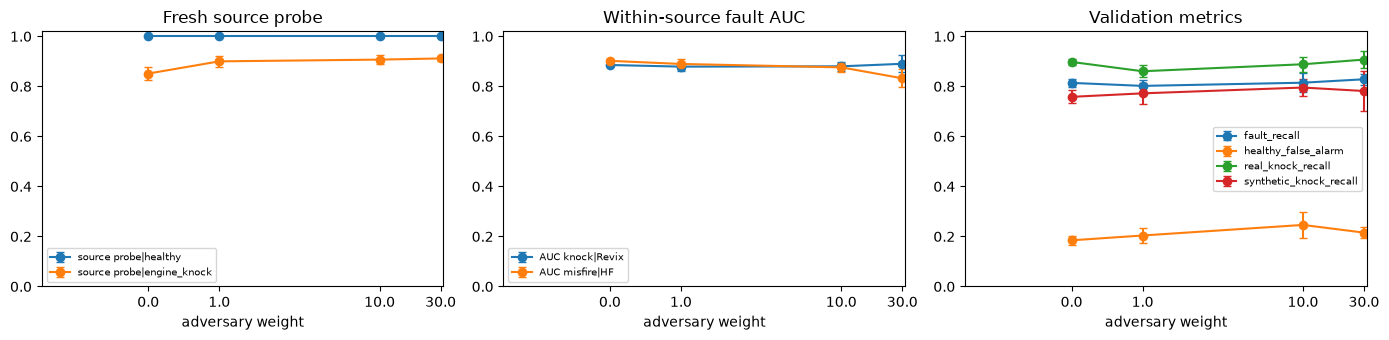

In [13]:
weights = [0.0, 1.0, 10.0, 30.0]
runs = []
for weight in weights:
    for seed in range(5):
        encoded, proba, info = fit_adversarial(weight, seed)
        runs.append({"lambda": weight, "seed": seed, **info, **score(val, proba.argmax(1)),
                     **within_source(proba), **source_probe(encoded)})
    print(f"Finished all five seeds for adversary weight {weight:g}")

adversarial = pd.DataFrame(runs)
adversarial.to_csv(RESULTS / "adversarial_runs.csv", index=False)
grouped = adversarial.groupby("lambda")
plot_groups = {
    "Fresh source probe": list(source_probe(X)),
    "Within-source fault AUC": list(WITHIN_SOURCE),
    "Validation metrics": ["fault_recall", "healthy_false_alarm", "real_knock_recall", "synthetic_knock_recall"],
}
summary_cols = ["kept_epoch", "adversary_train_acc", "misfire_recall",
                *[column for group in plot_groups.values() for column in group]]
summary = grouped[summary_cols].agg(["mean", "std"]).round(3)
display(summary.T)

_, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (title, columns) in zip(axes, plot_groups.items()):
    for column in columns:
        ax.errorbar(weights, grouped[column].mean(), yerr=grouped[column].std(), marker="o", capsize=3, label=column)
    ax.set(title=title, xlabel="adversary weight", ylim=(0, 1.02), xscale="symlog", xticks=weights, xticklabels=weights)
    ax.legend(fontsize=7)
plt.tight_layout()
show_plot("adversarial")

The training adversary's accuracy fell from about 100% to 81%, while the fresh probe still identified the source of healthy clips perfectly. Fault metrics changed little across weights. Validation against recordings collected under comparable conditions is still needed.

## Seed stability and final selection

Train both frozen heads with the same ten seeds. Choose the configuration with the highest mean validation fault recall among those with mean false alarms at or below 20%. If neither qualifies, use the higher mean recall. Evaluate both default-seed heads on the held-out sets after selection.

In [14]:
configs = {BASELINE: None, WEIGHTED: class_weights}
runs = []
for seed in range(10):
    for name, weights in configs.items():
        predict, _, _ = fit_linear(weights=weights, seed=seed)
        runs.append({"config": name, "seed": seed, **score(val, predict(val).argmax(1))})

stability = pd.DataFrame(runs)
stability["meets both targets"] = (stability["fault_recall"] >= MIN_RECALL) & (
    stability["healthy_false_alarm"] <= MAX_FALSE_ALARM)
stability.to_csv(RESULTS / "seed_stability.csv", index=False)

metrics = ["fault_recall", "healthy_false_alarm", "knock_recall", "misfire_recall"]
groups = stability.groupby("config")
summary = groups[metrics].agg(["mean", "std"]).round(3)
summary[("meets both targets", "seeds")] = groups["meets both targets"].sum()
display(summary)

paired = stability.pivot(index="seed", columns="config", values="fault_recall")
difference = paired[WEIGHTED] - paired[BASELINE]
print(f"Class weights improved recall in {(difference > 0).sum()}/{len(difference)} seeds "
      f"(mean change {difference.mean():+.3f}).")
means = groups[metrics].mean()
eligible = means[means["healthy_false_alarm"] <= MAX_FALSE_ALARM]
selected = (means if eligible.empty else eligible)["fault_recall"].idxmax()
print(f"Selected on validation: {selected}")

fault_recall        healthy_false_alarm         \
                              mean    std                mean    std   
config                                                                 
Baseline                     0.765  0.027               0.200  0.021   
Exp 2 (class weights)        0.847  0.017               0.196  0.030   

                      knock_recall        misfire_recall         \
                              mean    std           mean    std   
config                                                            
Baseline                     0.755  0.024          0.775  0.044   
Exp 2 (class weights)        0.713  0.017          0.981  0.030   

                      meets both targets  
                                   seeds  
config                                    
Baseline                               0  
Exp 2 (class weights)                  2

Class weights improved recall in 10/10 seeds (mean change +0.082).
Selected on validation: Exp 2 (class weights)


## Held-out evaluation

,selected,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,real_test_knock_recall,real_test_flagged_as_fault
Baseline,False,0.900,0.800,1.0,0.842,0.113,0.864,0.851,0.905,0.698,0.868,0.868
Exp 2 (class weights),True,0.906,0.812,1.0,0.861,0.113,0.862,0.857,0.905,0.721,0.868,0.868


154 mixed test clips and 38 real-knock test clips


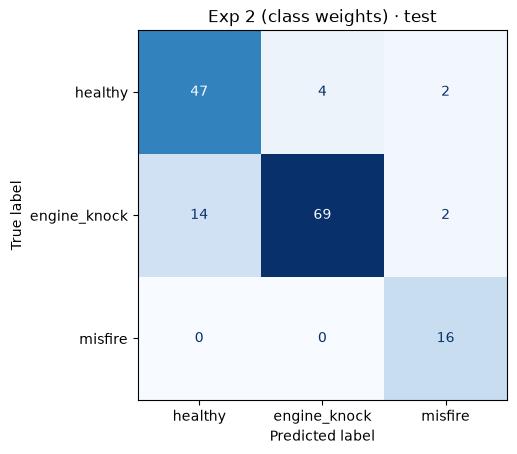

In [15]:
test, real_test = split["test"], split["real_test"]
final, test_predictions = {}, {}
for name, predict in {BASELINE: baseline, WEIGHTED: weighted}.items():
    pred = test_predictions[name] = predict(test).argmax(1)
    real_pred = predict(real_test).argmax(1)
    final[name] = {
        "selected": name == selected,
        **score(test, pred),
        "real_test_knock_recall": (real_pred == KNOCK).mean(),
        "real_test_flagged_as_fault": (real_pred != HEALTHY).mean(),
    }
final = pd.DataFrame.from_dict(final, orient="index")
final.to_csv(RESULTS / "final_test.csv")
display(final.round(3))
print(f"{len(test)} mixed test clips and {len(real_test)} real-knock test clips")
plot_confusion(test, test_predictions[selected], f"{selected} · test", "final_confusion")

**Recommendation: continue development.** The class-weighted frozen head reached 90.6% fault recall and 11.3% false alarms on the mixed test set, and caught 33 of 38 real knocks. It met both targets in only 2 of 10 validation seeds. The AST forward pass averaged 247 ms per clip on this machine's CPU. Before a shop pilot, collect healthy, knock, and misfire examples with the same recording setup across vehicles, then measure both missed faults and false alarms on a separate shop dataset.